# FL-BENCH-004.8 — Validation-based tuning of the four FL baselines

*Epic EPIC-001 · story fl_bench_004 · all results below are loaded from files produced by the task's experiment function and labelled MEASURED/SIMULATED; clients are virtual; data is synthetic.*

## 1. Research objective
Remove the 'untuned baseline' objection: select lr (all) and mu (FedProx) by validation F1 on a split of the TRAIN set, then compare tuned vs default on the untouched test set.

## 2. Scientific background
Baseline comparisons are only meaningful if every method gets comparable tuning effort [li2020fedprox, karimireddy2020, wang2020fednova, li2021niid]. Validation data is carved from train; test data is never used for selection.

References use keys of `docs/references/references_master.md` (status per entry).

## 3. Research questions
- **RQ1.** Does tuning change the ranking of FedAvg/FedProx/SCAFFOLD/FedNova?
- **RQ2.** Is the selected hyper-parameter interior to the grid or at its boundary?

## 4. Hypotheses
- **H1.** Tuned learning rates exceed the default 0.05 because the round budget is fixed.
- **H2.** Rankings shrink toward ties after tuning.

## 5. Mathematical formulation
theta* = argmax_theta mean_s F1_val(theta, seed s); grid: lr in {0.01,0.03,0.05,0.1,0.2,0.4,0.8}, mu in {0.001,0.01,0.05,0.1,0.5,1} (FedProx). Paired effect = F1_tuned - F1_default per seed.

## 6. Experimental environment

In [1]:
import os, sys, json, platform, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
os.environ.setdefault("MLFLOW_DISABLE_AGENT_HINT", "1")
def _find_root():
    p = Path(os.environ.get("FL_ROOT") or os.environ.get("RS_ROOT") or Path.cwd()).resolve()
    for q in [p, *p.parents]:
        if (q / "src" / "federated_learning").exists():
            return q
    raise RuntimeError("repository root not found; set RS_ROOT")
ROOT = _find_root()
sys.path.insert(0, str(ROOT / "src"))
STORY = "fl_bench_004"
_cands = [ROOT / "experiments" / "results" / STORY]
RES = next(c for c in _cands if c.exists())
import numpy as np, pandas as pd
import matplotlib; matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import Image, display
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
SEED = 0; np.random.seed(SEED)
def show_csv(name, n=12):
    p = RES / name
    if p.exists(): display(pd.read_csv(p).round(4).head(n))
    else: print("MISSING", name)
def show_fig(name):
    for base in (RES / "figures", RES):
        if (base / name).exists(): display(Image(filename=str(base / name))); return
    print("MISSING figure", name)
print("root:", ROOT, "| results:", RES)

root: /home/claude/fl_sprint | results: /home/claude/fl_sprint/experiments/results/fl_bench_004


In [2]:
import importlib.metadata as md
vers = {}
for p in ["numpy","scipy","scikit-learn","torch","tenseal","phe","pandas","matplotlib","cryptography","psutil","mlflow","opacus"]:
    try: vers[p] = md.version(p)
    except Exception: vers[p] = "not installed"
print(json.dumps(dict(python=platform.python_version(), platform=platform.platform(), versions=vers, seed=SEED, gpu="none (CPU only; GPU metrics NOT_MEASURED)"), indent=1))

{
 "python": "3.13.18",
 "platform": "Linux-6.18.44-fc-v338-x86_64-with-glibc2.39",
 "versions": {
  "numpy": "2.5.3",
  "scipy": "1.18.1",
  "scikit-learn": "1.9.1",
  "torch": "2.15.0",
  "tenseal": "0.3.18",
  "phe": "1.5.0",
  "pandas": "3.0.5",
  "matplotlib": "3.11.2",
  "cryptography": "50.0.1",
  "psutil": "7.2.2",
  "mlflow": "3.18.0",
  "opacus": "1.6.0"
 },
 "seed": 0,
 "gpu": "none (CPU only; GPU metrics NOT_MEASURED)"
}


## 7. Dataset description
Synthetic binary tabular dataset **SYN-IDS-v1** (scikit-learn `make_classification`, 40 features, 70:30 split). Chosen because no real IDS/clinical dataset was available in the sandbox. It has no clinical meaning; conclusions about absolute accuracy do not transfer.

In [3]:
from federated_learning.synthetic_data.generators.syn_ids_v1 import make_dataset, DATASET_ID
from federated_learning.data_partitioning.iid import partition_iid
from federated_learning.data_partitioning.dirichlet import partition_dirichlet
from federated_learning.data_partitioning.metrics import label_skew_stat
data = make_dataset(n_samples=6000, seed=SEED)
print(DATASET_ID, "train", data.X_train.shape, "test", data.X_test.shape, "positive rate", float(data.y_train.mean()))
print("NOTE: SYNTHETIC tabular data (not CIC-IDS-2017, not patient data); clients are VIRTUAL, not hospitals.")

SYN-IDS-v1 train (4200, 40) test (1800, 40) positive rate 0.40095238095238095
NOTE: SYNTHETIC tabular data (not CIC-IDS-2017, not patient data); clients are VIRTUAL, not hospitals.


## 8. Configuration and reproducibility settings
Seeds are fixed; each stored result carries `provenance` (experiment id, SHA-256 of the configuration, environment versions; `git_commit` is `null` because the workspace is not a git repository).

In [4]:
from federated_learning.training.config import FLConfig
cfg = FLConfig(rounds=5, local_epochs=1, seed=SEED)
print(cfg)

FLConfig(algo='fedavg', rounds=5, local_epochs=1, lr=0.05, batch_size=32, participation=1.0, mu=0.0, hidden=32, act='relu', seed=0, hetero_epochs=False, eval_every=1, server_lr=1.0)


## 9. Data preparation
Partitioning into virtual clients (IID or Dirichlet label skew) is performed by `federated_learning.data_partitioning`.

In [5]:
parts_iid = partition_iid(data.y_train, 10, SEED)
parts_dir = partition_dirichlet(data.y_train, 10, 0.3, SEED)
print('label-skew statistic IID:', round(label_skew_stat(data.y_train, parts_iid),3), ' Dirichlet(0.3):', round(label_skew_stat(data.y_train, parts_dir),3))

label-skew statistic IID: 0.019  Dirichlet(0.3): 0.363


## 10. Implementation
Reusable code lives in `src/federated_learning/` (`experiments/ext.py`, `real_data.split_validation`, `stats.py`). The cell below exercises it live (small, fast, deterministic) and asserts correctness.

In [6]:
from federated_learning.preprocessing.splits import split_validation
from federated_learning.pipelines.experiments.ext import tune
val = split_validation(data, 0.25, SEED)
best, tab = tune(val, "fedavg", 10, "0.3", 3, 1, [100])
print("best (3-round smoke test, NOT the reported tuning):", best, "| configs evaluated:", len(tab)); assert len(tab) == 7

best (3-round smoke test, NOT the reported tuning): {'lr': 0.8, 'mu': 0.0} | configs evaluated: 7


## 11. Experiment execution
The full experiment was executed by `python -m federated_learning.pipelines.experiments.run_all --task FL-BENCH-004.8` (see `logs/`). Its raw per-run results are loaded here; they are not re-computed inside the notebook.

In [7]:
show_csv('task_4_8_tuning_grid.csv')
show_csv('task_4_8_runs.csv')

,algo,lr,mu,val_f1,val_loss
0,fedavg,0.01,0.000,0.7200,0.4204
1,fedavg,0.03,0.000,0.8177,0.3169
2,fedavg,0.05,0.000,0.8417,0.2926
3,fedavg,0.10,0.000,0.8541,0.2926
4,fedavg,0.20,0.000,0.8634,0.3301
5,fedavg,0.40,0.000,0.8621,0.3833
6,fedavg,0.80,0.000,0.8675,0.4164
7,fedprox,0.01,0.001,0.7196,0.4205
8,fedprox,0.01,0.010,0.7189,0.4212
9,fedprox,0.01,0.050,0.7159,0.4245


,algo,setting,seed,lr,mu,acc,f1,auc
0,fedavg,default,0,0.05,0.05,0.8897,0.8547,0.9561
1,fedavg,tuned,0,0.80,0.00,0.8958,0.8668,0.9557
2,fedavg,default,1,0.05,0.05,0.9019,0.8734,0.9615
3,fedavg,tuned,1,0.80,0.00,0.8944,0.8666,0.9580
4,fedavg,default,2,0.05,0.05,0.8497,0.7851,0.9405
5,fedavg,tuned,2,0.80,0.00,0.8633,0.8146,0.9410
6,fedavg,default,3,0.05,0.05,0.8461,0.7753,0.9399
7,fedavg,tuned,3,0.80,0.00,0.7939,0.7264,0.8674
8,fedavg,default,4,0.05,0.05,0.8994,0.8683,0.9606
9,fedavg,tuned,4,0.80,0.00,0.9056,0.8811,0.9601


## 12. Metrics collection
Metric definitions: validation F1 (selection); test acc/F1/AUC over 10 seeds (evaluation).

In [8]:
show_csv('task_4_8_summary.csv')

,algo,setting,lr,mu,acc,acc_ci,f1,f1_ci,auc,auc_ci
0,fedavg,default,0.05,0.05,0.8839,"[0.8663, 0.9015]",0.8431,"[0.8124, 0.8737]",0.9550,"[0.9485, 0.9615]"
1,fedavg,tuned,0.80,0.00,0.8831,"[0.8582, 0.9080]",0.8481,"[0.8128, 0.8834]",0.9472,"[0.9266, 0.9678]"
2,fedprox,default,0.05,0.05,0.8808,"[0.8632, 0.8985]",0.8391,"[0.8088, 0.8693]",0.9526,"[0.9448, 0.9605]"
3,fedprox,tuned,0.20,0.01,0.8917,"[0.8803, 0.9031]",0.8574,"[0.8379, 0.8769]",0.9573,"[0.9535, 0.9611]"
4,scaffold,default,0.05,0.05,0.8986,"[0.8868, 0.9103]",0.8729,"[0.8606, 0.8852]",0.9593,"[0.9529, 0.9656]"
5,scaffold,tuned,0.05,0.00,0.8986,"[0.8868, 0.9103]",0.8729,"[0.8606, 0.8852]",0.9593,"[0.9529, 0.9656]"
6,fednova,default,0.05,0.05,0.8948,"[0.8836, 0.9060]",0.8637,"[0.8471, 0.8803]",0.9592,"[0.9547, 0.9638]"
7,fednova,tuned,0.10,0.00,0.8948,"[0.8859, 0.9036]",0.8633,"[0.8478, 0.8788]",0.9608,"[0.9577, 0.9639]"


## 13. Statistical analysis
Paired Wilcoxon / t (tuned vs default, by seed), Friedman + Holm-corrected pairwise tests across the tuned algorithms.

In [9]:
show_csv('task_4_8_tuned_vs_default_tests.csv'); show_csv('task_4_8_tuned_pairwise.csv')

,n,mean_diff,dz,wilcoxon_p,ttest_p,algo,metric,note
0,10,0.0050,0.2196,0.1934,0.5049,fedavg,f1,"tuned - default, paired by seed"
1,10,0.0183,0.9901,0.0059,0.0121,fedprox,f1,"tuned - default, paired by seed"
2,10,0.0000,0.0000,1.0000,1.0000,scaffold,f1,"tuned - default, paired by seed"
3,10,-0.0004,-0.0256,0.9219,0.9373,fednova,f1,"tuned - default, paired by seed"


,n,mean_diff,dz,wilcoxon_p,ttest_p,a,b,holm_p
0,10,-0.0093,-0.2494,0.9219,0.4506,fedavg,fedprox,1.0000
1,10,-0.0248,-0.6131,0.1309,0.0845,fedavg,scaffold,0.7852
2,10,-0.0152,-0.4411,0.2754,0.1965,fedavg,fednova,1.0000
3,10,-0.0155,-0.5104,0.3750,0.1410,fedprox,scaffold,1.0000
4,10,-0.0059,-0.2113,0.6953,0.5207,fedprox,fednova,1.0000
5,10,0.0096,0.5586,0.1934,0.1111,scaffold,fednova,0.9668


## 14. Visualizations

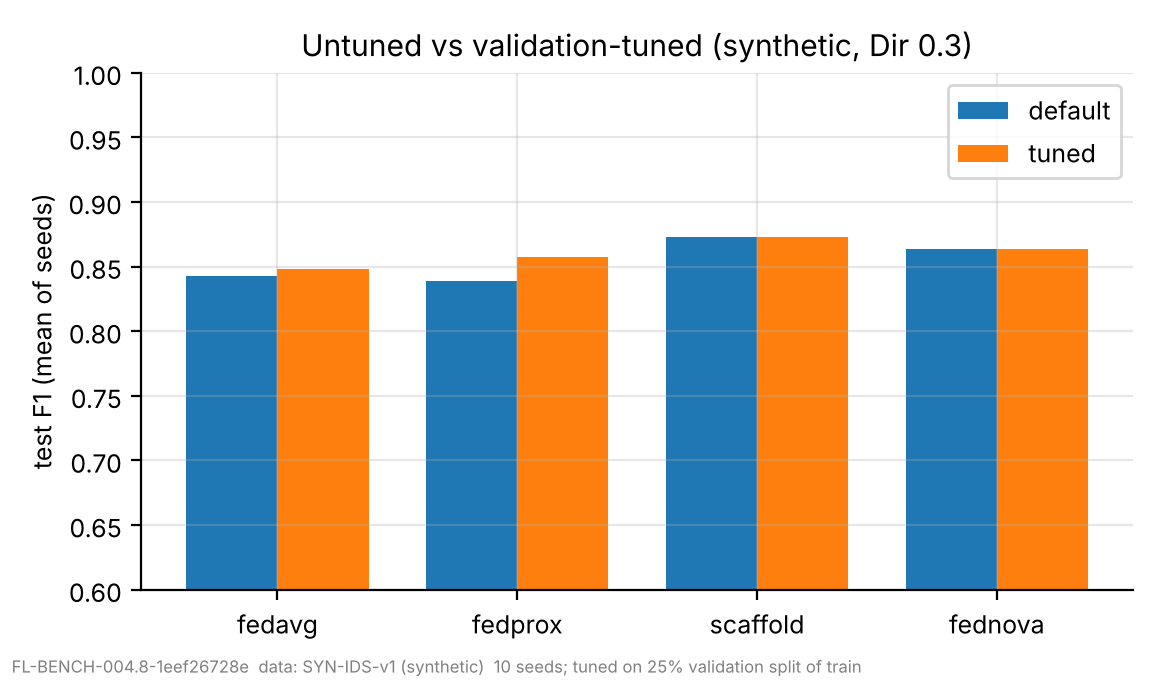

In [10]:
show_fig('task_4_8_tuning.png')

## 15. Interpretation of results
The numbers are computed in the next cell from the stored data; the text interprets only what that cell prints.

Boundary-optimum rows are flagged in the printed table (selected lr equals the largest grid value).

In [11]:
g = pd.read_csv(RES / 'task_4_8_tuning_grid.csv'); best = g.loc[g.groupby('algo')['val_f1'].idxmax()]; best['at_lr_grid_edge'] = best['lr'] == g['lr'].max(); display(best.round(4))

,algo,lr,mu,val_f1,val_loss,at_lr_grid_edge
6,fedavg,0.80,0.00,0.8675,0.4164,True
59,fednova,0.10,0.00,0.8312,0.3693,False
32,fedprox,0.20,0.01,0.8640,0.3039,False
51,scaffold,0.05,0.00,0.8719,0.2681,False


## 16. Limitations
- Grid truncated at lr=0.8: where the optimum is at the edge, true optimum may be larger.
- Fixed round budget favours aggressive learning rates.
- Only lr/mu tuned (batch size, epochs, hidden width fixed).
- Synthetic data, virtual clients on one machine, 2 CPU cores, no GPU; no real network. Comm. bytes are logical payload sizes.
- No regulatory/compliance conclusion can be drawn from this notebook.

## 17. Conclusions
See results_and_discussion.md.

**Jira acceptance:** see `docs/fl_bench_004/results_and_discussion.md` for the criterion-by-criterion verdict (MET / PARTIALLY MET / NOT MET).

## 18. References
`li2020fedprox`, `karimireddy2020`, `wang2020fednova`, `li2021niid`, `demsar2006` — details in `docs/fl_bench_004/references.md`.